# EpiAI 一站式教程
从原始数据到部署预测 + 可视化

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
from pathlib import Path

from EpiAI import ForecastTask
from EpiAI.dataset import TimeSplit
from EpiAI.viz import plot_test_predictions, plot_forecast

## 1. 加载数据

In [2]:
DATA_PATH = Path.home() / "infective_disease" / "pingtai" / "merged_clean.csv"
DISEASE = "登革热 Dengue fever"

df_raw = pd.read_csv(DATA_PATH)
df_raw["Year/Month"] = pd.to_datetime(df_raw["Year/Month"])
df = (
    df_raw.query("Diseases == @DISEASE")
    [["Year/Month", "Case number"]]
    .rename(columns={"Year/Month": "time", "Case number": "cases"})
    .reset_index(drop=True)
)
df = df[df["time"].dt.year >= 2010].reset_index(drop=True)
print(f"数据: {len(df)} 行, {df['time'].min().date()} → {df['time'].max().date()}")

数据: 196 行, 2010-01-01 → 2026-04-01


## 2. 定义预测任务

In [3]:
task = ForecastTask(
    data=df,
    target="cases",
    time_col="time",
    freq="MS",
    horizon=12,
    split=TimeSplit(train_end="2024-05-01", val_end="2025-05-01"),
)
print(f"Task: {task}")
print(f"季节周期: {task.freq_to_season_length()} 期/年")

Task: ForecastTask(target=['cases'], freq=MS, horizon=12)
季节周期: 12 期/年


## 3. 批量训练 + 排行榜

In [4]:
from EpiAI.models.registry import get, list_models
model_names = ['arima',
 'autoformer',
 'bsts',
 'cnn',
 'cnn-lstm',
 'dlinear',
 'ets',
#  'lgbm',
 'linearreg',
 'lstm',
 'mlp',
 'prophet',
 'resnet',
 'rf',
 'serfling',
 'sf_adida',
 'sf_arch',
 'sf_arima',
 'sf_auto_arima',
 'sf_auto_ces',
 'sf_auto_ets',
 'sf_auto_regressive',
 'sf_auto_tbats',
 'sf_auto_theta',
 'sf_croston_classic',
 'sf_croston_optimized',
 'sf_croston_sba',
 'sf_garch',
 'sf_historic_average',
 'sf_holt',
 'sf_holt_winters',
 'sf_imapa',
 'sf_mstl',
 'sf_naive',
 'sf_random_walk_drift',
 'sf_seasonal_exp_smoothing',
 'sf_seasonal_exp_smoothing_optimized',
 'sf_seasonal_naive',
 'sf_seasonal_window_average',
 'sf_simple_exp_smoothing',
 'sf_simple_exp_smoothing_optimized',
 'sf_tbats',
 'sf_theta',
 'sf_theta_dynamic',
 'sf_theta_dynamic_optimized',
 'sf_theta_optimized',
 'sf_tsb',
 'sf_window_average',
 'stlm',
 'svr',
 'tcn',
 'timesnet',
 'transformer',
 'xgb'
 ]

In [5]:
vault = task.compare(model_names, cache_dir="./test")
print("\n排行榜（按 R² 排序）:")
display(vault.summary())

  arima                           ← 缓存  MAE=587  R²=0.589  PearsonR=0.841
  autoformer                      ← 缓存  MAE=813  R²=-0.517  PearsonR=0.651
  bsts                            ← 缓存  MAE=1266  R²=-4.368  PearsonR=0.916
  cnn                             ← 缓存  MAE=336  R²=0.814  PearsonR=0.910
  cnn-lstm                        ← 缓存  MAE=836  R²=-0.565  PearsonR=-0.048
  dlinear                         ← 缓存  MAE=601  R²=0.039  PearsonR=0.535
  ets                             ← 缓存  MAE=478  R²=0.782  PearsonR=0.970
  linearreg                       ← 缓存  MAE=495  R²=0.628  PearsonR=0.862
  lstm                            ← 缓存  MAE=822  R²=-0.546  PearsonR=0.668
  mlp                             ← 缓存  MAE=643  R²=0.064  PearsonR=0.848
  prophet                         ← 缓存  MAE=387  R²=0.855  PearsonR=0.967
  resnet                          ← 缓存  MAE=404  R²=0.764  PearsonR=0.931
  rf                              ← 缓存  MAE=501  R²=0.518  PearsonR=0.932
  serfling                      

,paradigm,MAE,RMSE,MAPE,R2,PearsonR,n
model,,,,,,,
sf_auto_ces,ts,271.478027,486.684814,31.448820,0.808236,0.981065,12
sf_seasonal_exp_smoothing,ts,229.779984,313.855774,51.863110,0.920250,0.980784,12
sf_mstl,ts,710.879456,762.103149,328.870177,0.529783,0.974462,12
sf_auto_ets,ts,583.824707,626.709900,334.494662,0.682017,0.970803,12
sf_seasonal_window_average,ts,252.229187,410.308289,47.249067,0.863701,0.970583,12
ets,ts,477.592194,519.234924,298.268795,0.781728,0.970391,12
sf_holt_winters,ts,336.334015,391.961792,202.819920,0.875618,0.970364,12
sf_theta_dynamic_optimized,ts,796.050598,840.984070,470.833540,0.427406,0.970026,12
sf_theta,ts,833.764465,877.970154,492.347097,0.375934,0.969142,12


In [9]:
from EpiAI.evaluate import compare_risk_methods

report = compare_risk_methods(
    vault=vault,
    bundle=task.build_bundle(),
    task=task,
    risk_methods=["quantile", "zscore"],
    event_threshold=0.70,    # 事件 = 实际值 > 历史 90% 分位
)
report.sort_values(by="precision", ascending=False)

,model,risk_method,hit_rate,fa_rate,precision,recall,f1,n_alerts,n_events,tp,fp,fn,tn
5,bsts,zscore,0.166667,0.166667,0.500000,0.166667,0.250000,2,6,1,1,5,5
71,sf_seasonal_exp_smoothing_optimized,zscore,0.166667,0.166667,0.500000,0.166667,0.250000,2,6,1,1,5,5
73,sf_seasonal_naive,zscore,0.166667,0.166667,0.500000,0.166667,0.250000,2,6,1,1,5,5
70,sf_seasonal_exp_smoothing_optimized,quantile,0.166667,0.166667,0.500000,0.166667,0.250000,2,6,1,1,5,5
104,xgb,quantile,0.666667,0.833333,0.444444,0.666667,0.533333,9,6,4,5,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,svr,zscore,0.000000,0.000000,NaN,0.000000,NaN,0,6,0,0,6,6
98,tcn,quantile,0.000000,0.000000,NaN,0.000000,NaN,0,6,0,0,6,6
99,tcn,zscore,0.000000,0.000000,NaN,0.000000,NaN,0,6,0,0,6,6
102,transformer,quantile,0.000000,0.000000,NaN,0.000000,NaN,0,6,0,0,6,6


## 4. 测试集预测对比图

真实值（黑线） vs 各模型在测试集上的预测值（散点+虚线），图例附带 Pearson r。

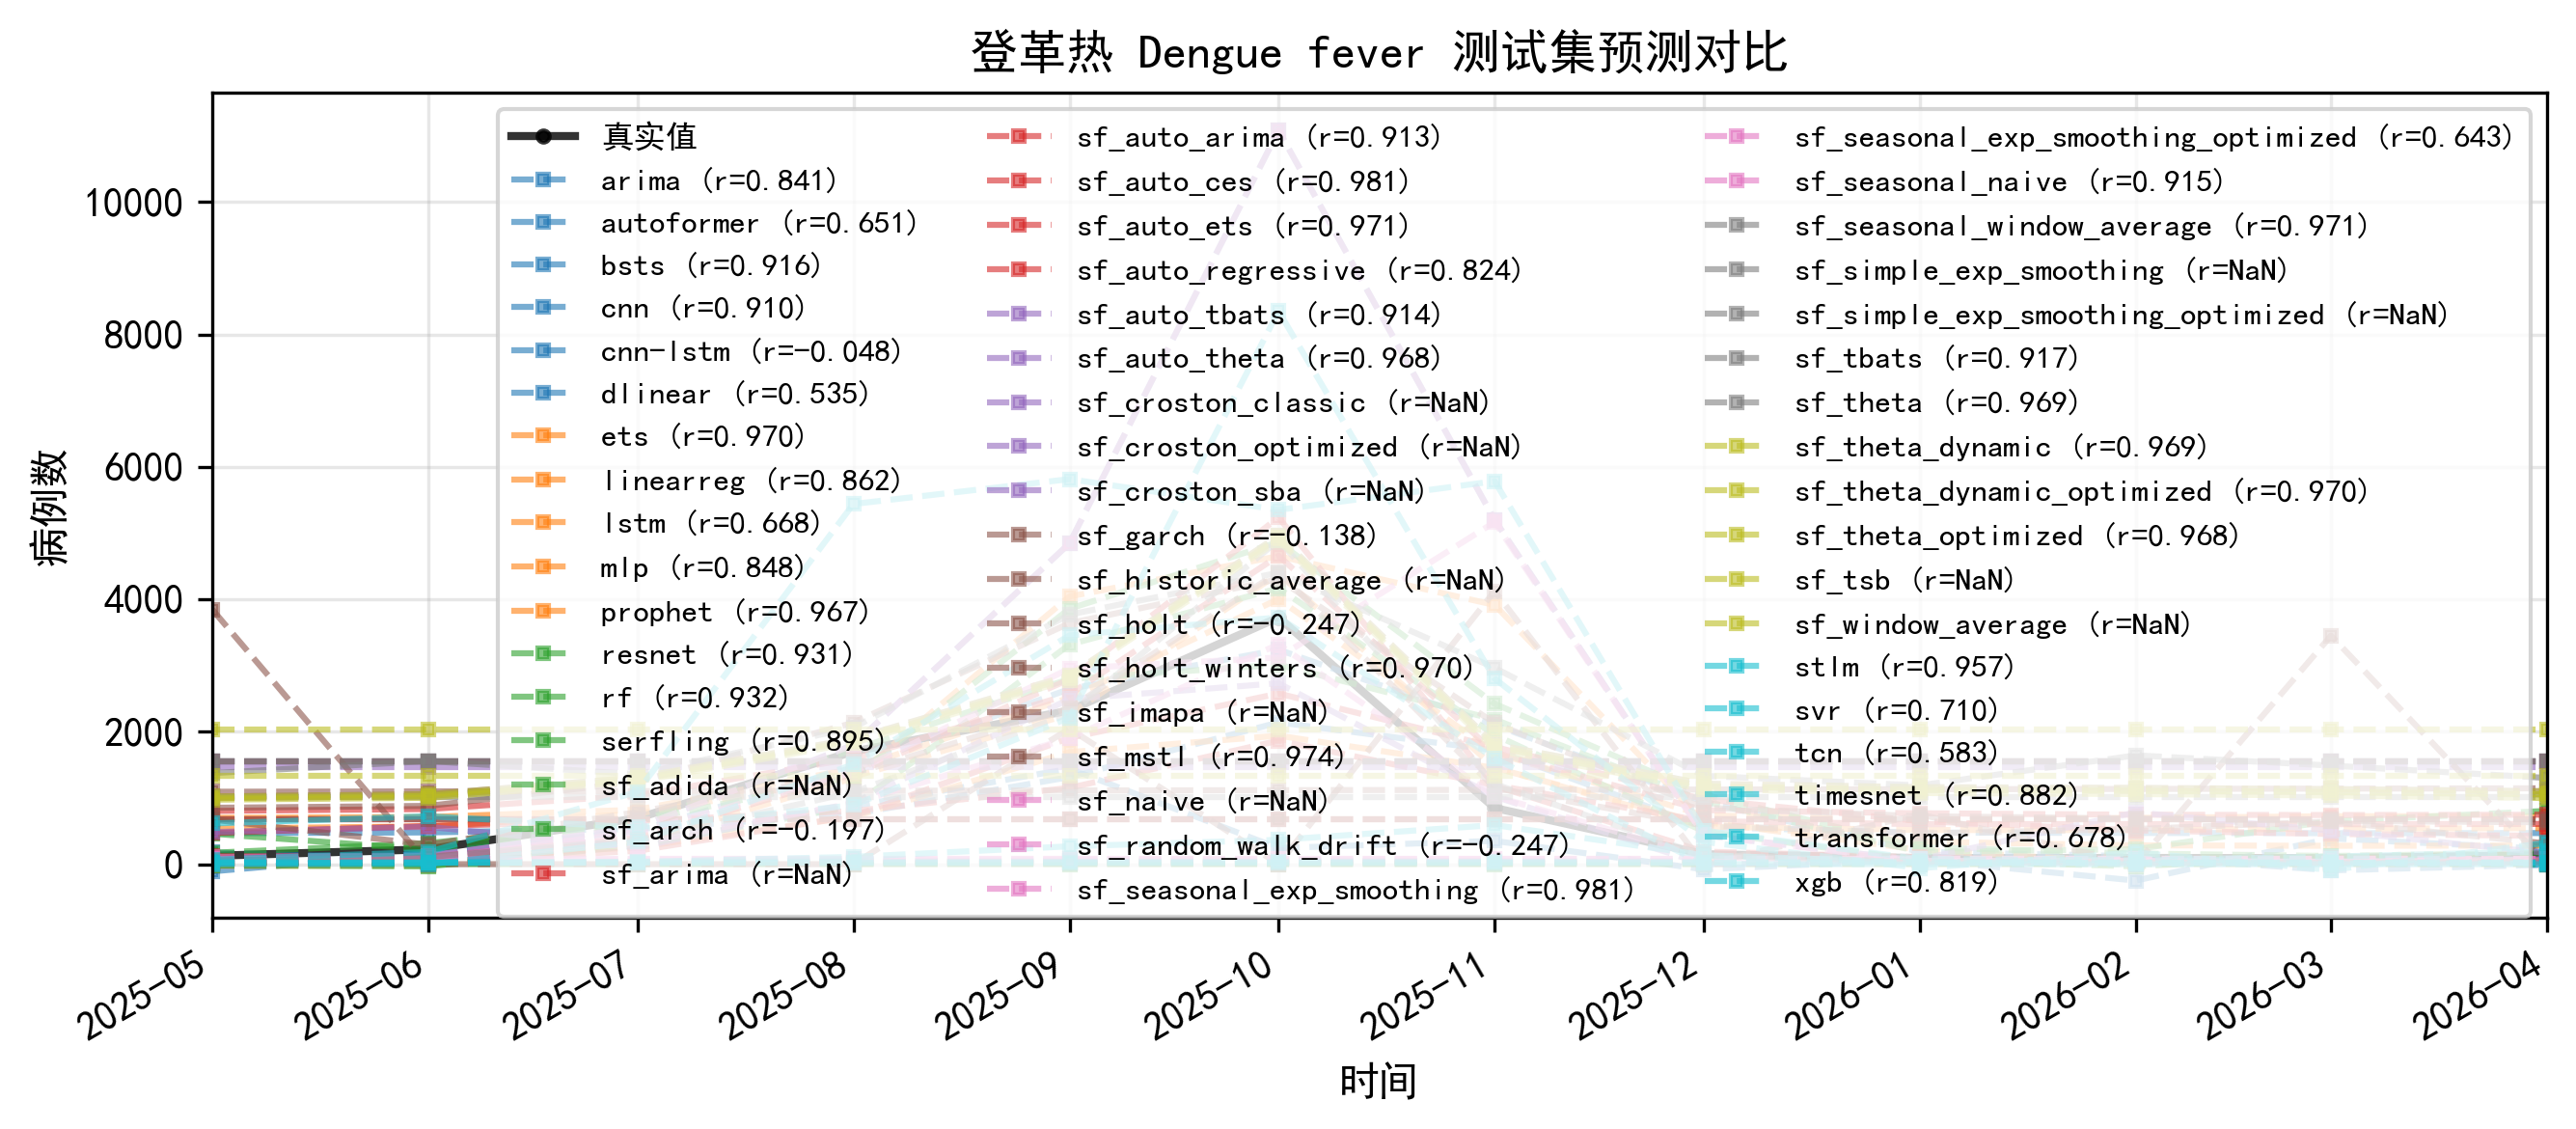

In [10]:
plot_test_predictions(
    bundle=task.build_bundle(),
    vault=vault,
    title=f"{DISEASE} 测试集预测对比",
)

## 5. 部署 + 风险评分

In [11]:
best_model = vault.best("R2")
print(f"最佳模型: {best_model}")

runtime = task.deploy(best_model, vault, risk=["quantile", "zscore"])
print(f"Runtime: {runtime}")
print(f"风险算法: {list(runtime.risk_scorers.keys())}")

最佳模型: sf_seasonal_exp_smoothing
Runtime: DeploymentRuntime(53 models, 196 rows)
风险算法: ['quantile', 'zscore']


In [13]:
report

,model,horizon,hit_rate,fa_rate,precision,recall,f1,n_alerts,n_events,tp,fp,fn,tn
0,prophet,1,0.000000,0.666667,0.000000,0.000000,NaN,2,4,0,2,4,1
1,prophet,2,0.000000,0.250000,0.000000,0.000000,NaN,1,3,0,1,3,3
2,prophet,3,0.000000,0.400000,0.000000,0.000000,NaN,2,2,0,2,2,3
3,prophet,4,0.000000,0.750000,0.000000,0.000000,NaN,3,3,0,3,3,1
4,prophet,5,0.000000,0.800000,0.000000,0.000000,NaN,4,2,0,4,2,1
5,prophet,6,0.000000,1.000000,0.000000,0.000000,NaN,5,2,0,5,2,0
6,sf_auto_ets,1,0.000000,1.000000,0.000000,0.000000,NaN,3,4,0,3,4,0
7,sf_auto_ets,2,0.333333,0.500000,0.333333,0.333333,0.333333,3,3,1,2,2,2
8,sf_auto_ets,3,0.000000,0.600000,0.000000,0.000000,NaN,3,2,0,3,2,2
9,sf_auto_ets,4,0.000000,0.750000,0.000000,0.000000,NaN,3,3,0,3,3,1


## 6. 未来预测图

历史曲线（最近 20 期） + 多模型未来预测 + 风险等级。

In [ ]:
vault.metrics

,paradigm,MAE,RMSE,MAPE,R2,PearsonR,n
model,,,,,,,
arima,ts,587.166931,712.734009,199.094391,0.588731,0.840505,12
autoformer,torch,813.179443,1368.648071,84.909075,-0.516542,0.651015,12
bsts,ts,1265.583374,2575.054443,114.782035,-4.368386,0.915520,12
cnn,torch,335.755585,479.436676,115.716028,0.813906,0.909803,12
cnn-lstm,torch,835.717346,1390.539551,92.087674,-0.565444,-0.047501,12
dlinear,torch,601.482727,1089.661377,110.546899,0.038711,0.535363,12
ets,ts,477.592194,519.234924,298.268795,0.781728,0.970391,12
linearreg,sklearn,494.623444,678.140076,125.446856,0.627686,0.861506,12
lstm,torch,821.685486,1381.958496,84.891063,-0.546183,0.667984,12


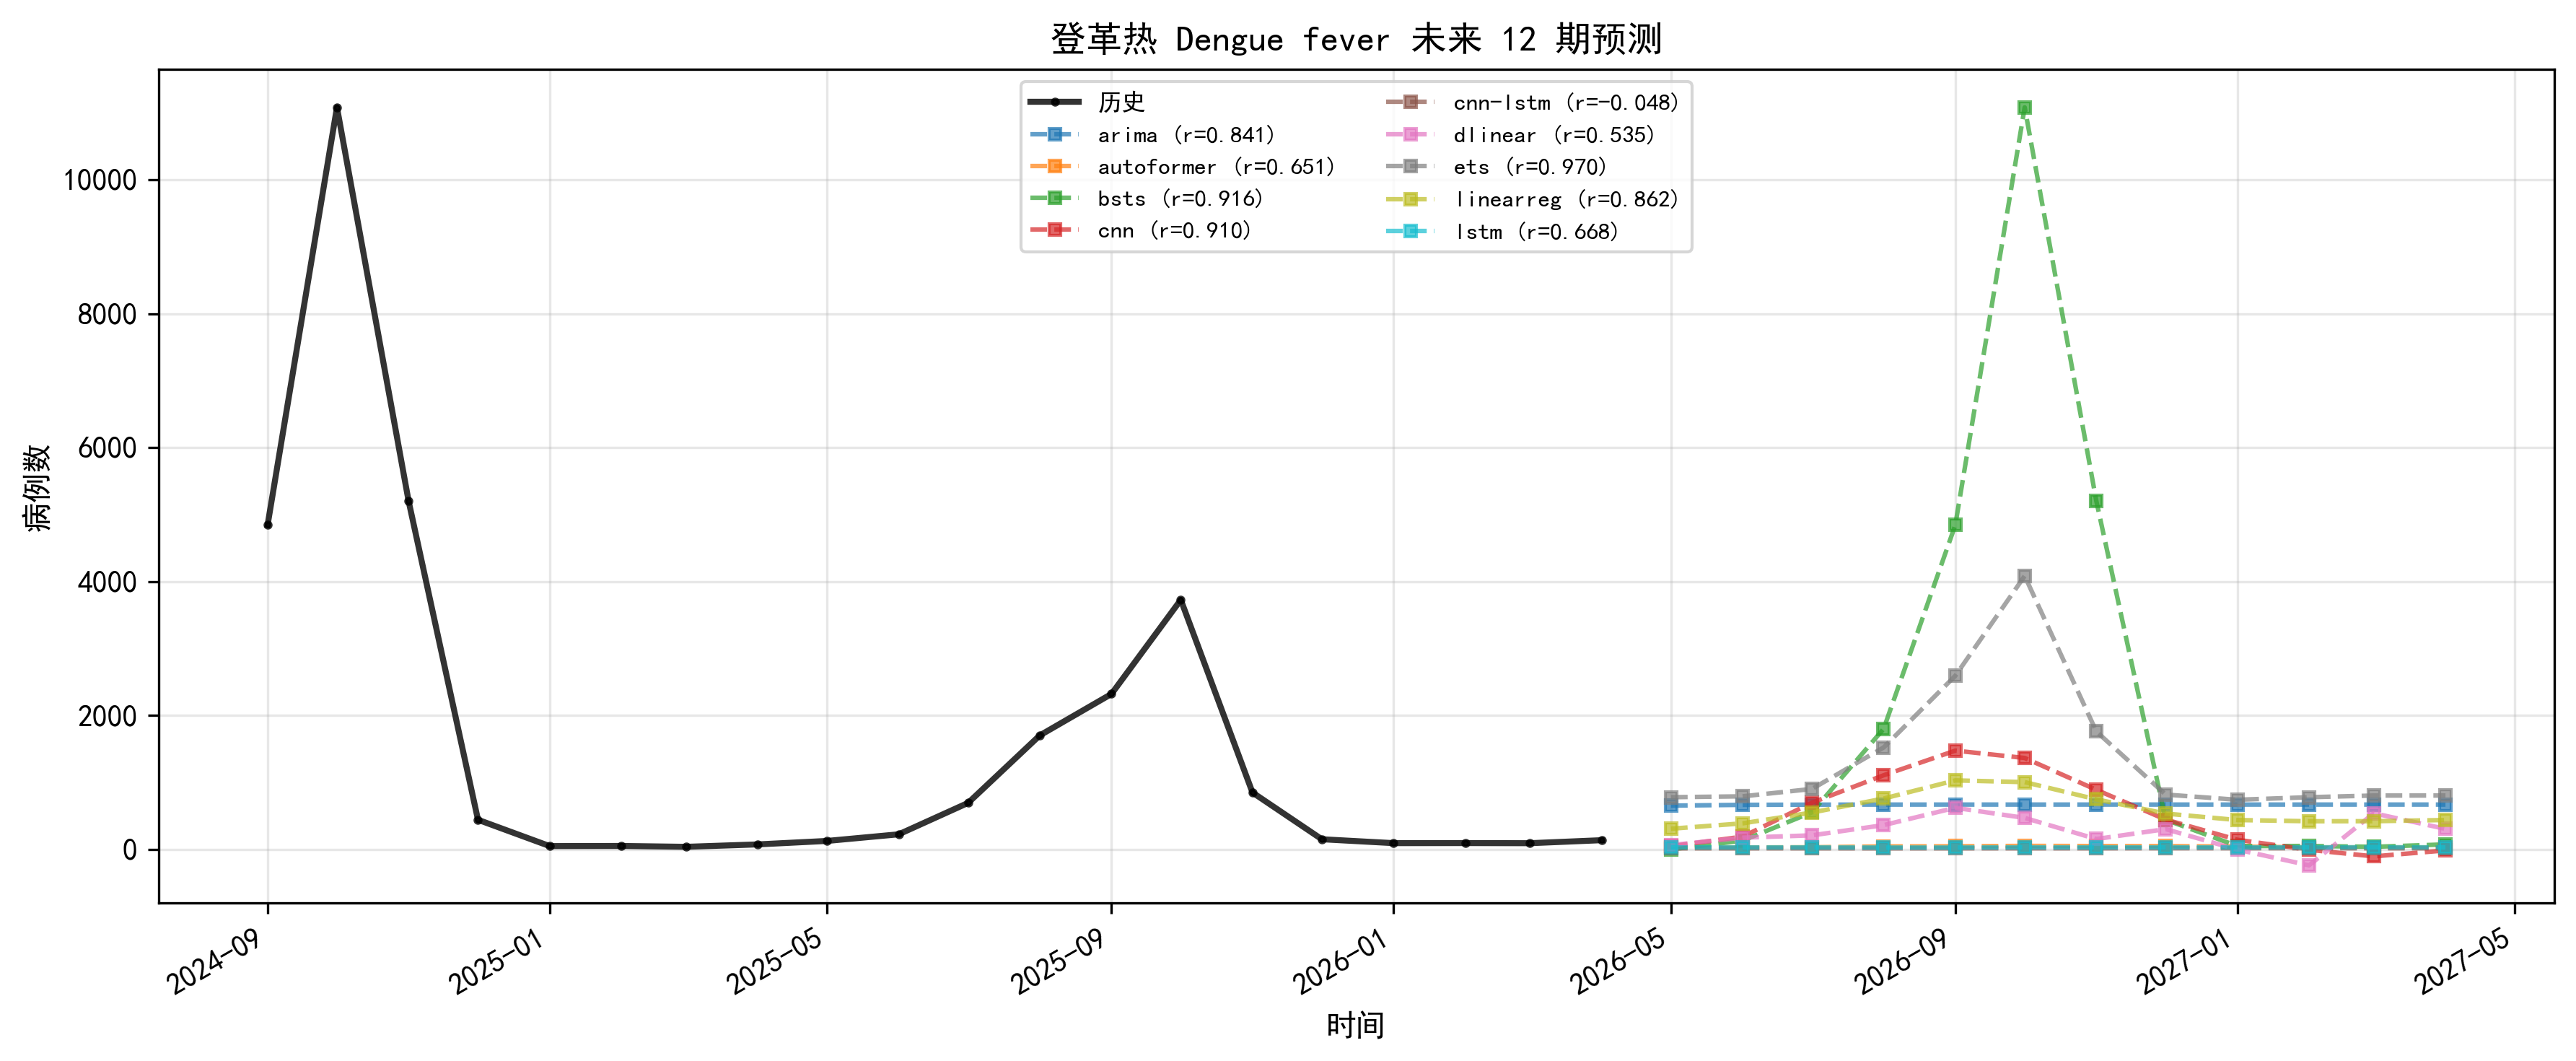

In [ ]:
hist = runtime.data_table.tail(20)
pred = runtime.predict(horizon=12, level=95)

plot_forecast(
    hist_df=hist,
    pred_df=pred,
    metrics_df=vault.metrics,
    title=f"{DISEASE} 未来 12 期预测",
    top_n=9
)

In [ ]:
runtime.refit([best_model])

  sf_seasonal_exp_smoothing       MAE=230  R²=0.920  PearsonR=0.981
  risk_quantile refit OK
  risk_zscore refit OK

全部重训完成，共 1 个模型。


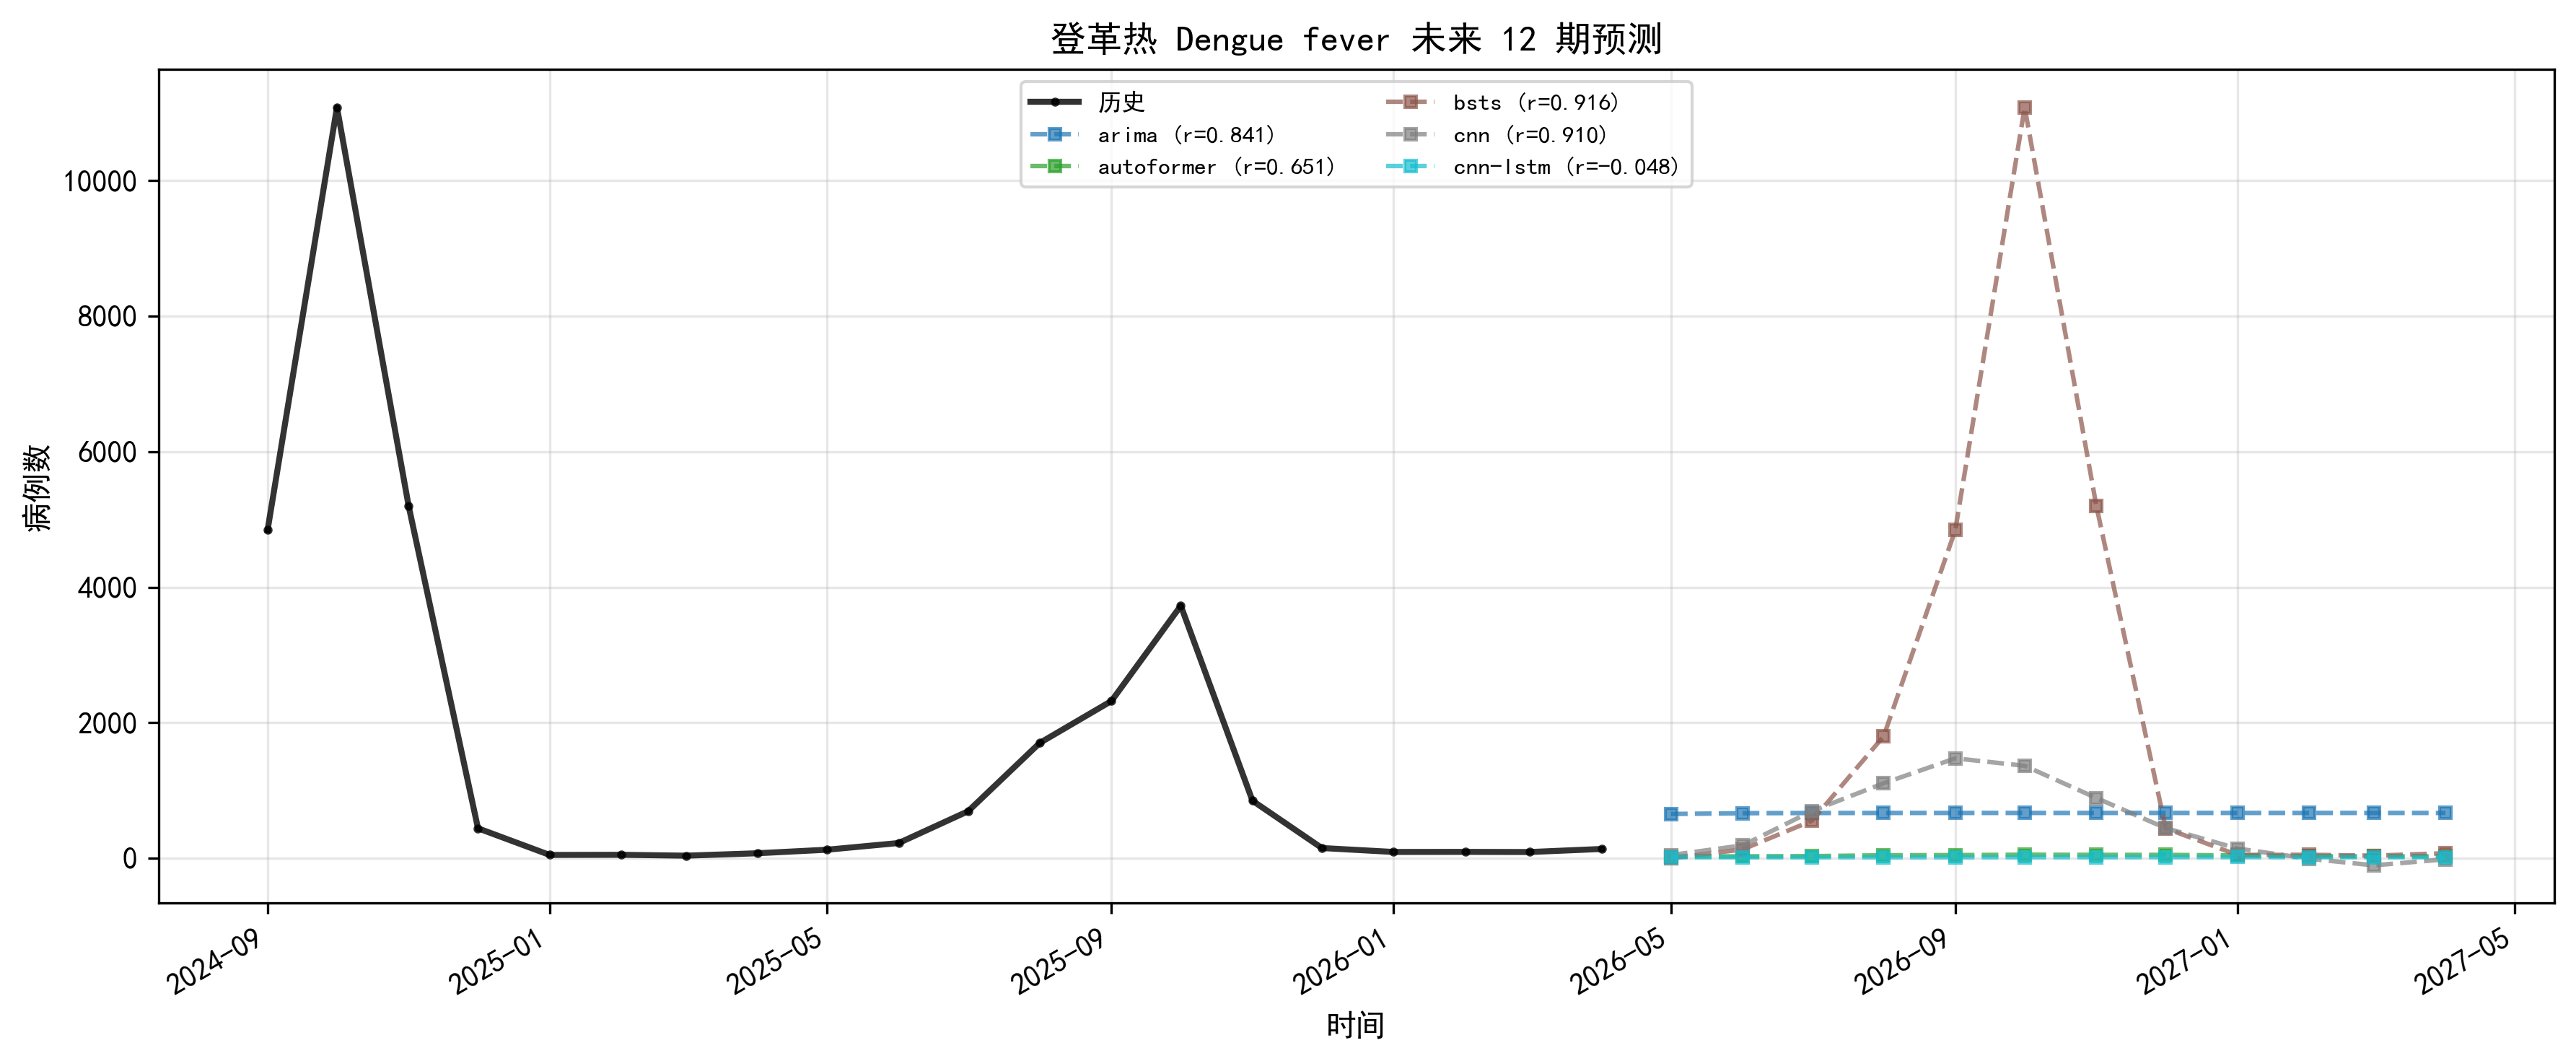

In [ ]:
hist = runtime.data_table.tail(20)
pred = runtime.predict(horizon=12, level=95)

plot_forecast(
    hist_df=hist,
    pred_df=pred,
    metrics_df=vault.metrics,
    title=f"{DISEASE} 未来 12 期预测",
)

In [15]:
pred

,time,arima,autoformer,bsts,cnn,cnn-lstm,dlinear,ets,linearreg,lstm,...,sf_croston_optimized_zscore,arima_zscore,linearreg_zscore,mlp_zscore,sf_auto_regressive_zscore,svr_zscore,xgb_zscore,prophet_zscore,sf_simple_exp_smoothing_optimized_zscore,sf_arch_zscore
0,2026-05-01,653.371460,26.644653,0.0,46.719307,15.199421,63.977547,779.035950,308.076141,29.070801,...,0,3,3,0,3,0,1,3,3,0
1,2026-06-01,664.828613,28.308146,130.0,189.799744,15.354579,174.634354,791.898560,388.618866,28.351412,...,0,3,1,0,1,0,3,2,3,0
2,2026-07-01,667.861328,31.307196,554.0,696.742188,15.474942,209.259064,902.483826,550.066406,28.228224,...,0,0,0,0,0,0,3,1,1,0
3,2026-08-01,668.664124,44.228455,1801.0,1106.727905,14.803183,361.790161,1522.283203,758.939697,26.989847,...,0,0,0,0,0,0,3,0,0,0
4,2026-09-01,668.876587,46.311806,4845.0,1474.687012,15.372785,621.120422,2592.993164,1030.070801,27.035168,...,0,0,0,0,0,0,1,0,0,0
5,2026-10-01,668.932861,52.195316,11083.0,1364.910889,15.654147,469.645844,4083.621338,1004.331055,29.620365,...,0,0,0,0,0,0,0,0,0,0
6,2026-11-01,668.947754,49.773212,5201.0,889.185669,15.924664,154.469238,1760.351196,746.925598,28.761127,...,0,0,0,0,0,0,0,0,0,0
7,2026-12-01,668.951660,49.583153,442.0,444.731140,16.950550,302.147400,818.174377,534.780029,30.232180,...,0,3,3,2,3,0,0,3,3,0
8,2027-01-01,668.952698,41.452515,49.0,143.619736,17.078751,-3.686878,740.519470,437.984131,29.700123,...,0,3,3,0,3,0,0,3,3,0
9,2027-02-01,668.953003,29.064566,51.0,-7.006560,16.905624,-238.617432,778.831116,420.105591,30.159061,...,0,3,3,3,3,0,0,3,3,0
